# 01 — Compter les bigrammes : un premier modèle de langage sans apprentissage

**Chapitre 1** · durée conseillée : 30 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/fr/chapitre_1/01_compter_les_bigrammes.ipynb)

![Parcours du chapitre](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_1/figures/00_parcours.png)

> **Fil rouge du chapitre :** un modèle bigramme peut s'obtenir de deux façons. On peut **compter** les transitions dans les données et en tirer une table de probabilités. On peut aussi **apprendre** une matrice de poids par descente de gradient. Les deux chemins mènent presque à la même table (notebook 06).

**À la fin de ce notebook, vous saurez :**
1. compter les transitions entre caractères dans une matrice `N` de taille `(27, 27)` ;
2. transformer ces comptages en probabilités conditionnelles `P(suivant | courant)` ;
3. tirer un caractère au hasard avec `torch.multinomial` et générer des prénoms ;
4. expliquer pourquoi ces prénoms sont plausibles localement mais pas globalement.

**Convention :** le symbole `.` marque le **début** et la **fin** d'un prénom. On ne prédit que le **caractère suivant**, connaissant le caractère courant.

## 0. Le défi : inventer de nouveaux prénoms

Un **modèle de langage** attribue une probabilité au **prochain symbole**, compte tenu d'un contexte. Ici, le contexte se réduit à **un seul caractère**. C'est un **modèle bigramme** (*bi* = deux : le caractère courant et le suivant).

L'idée n'est pas neuve : en 1948, Claude Shannon fabriquait déjà du « faux anglais » en tirant chaque lettre selon la lettre précédente. Les grands modèles de langage actuels font la même chose, avec un contexte de plusieurs milliers de *tokens* au lieu d'un caractère.

Nous utilisons `names.txt`, environ 32 000 prénoms anglophones (le jeu de données du projet *makemore* d'Andrej Karpathy). Le petit module `bigramme.py` lit le fichier à côté du notebook, ou dans le dossier `corpus/` du dépôt, et le télécharge sinon.

In [1]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme bigramme.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigramme.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/fr/chapitre_1

In [2]:
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigramme
from bigramme import SEED, plot_matrice_caracteres

words = bigramme.charger_prenoms()
print(f"{len(words):,} prénoms")
print("Dix premiers :", words[:10])
longueurs = [len(w) for w in words]
print(f"Longueur : min {min(longueurs)}, max {max(longueurs)}, moyenne {sum(longueurs)/len(longueurs):.1f}")

32,033 prénoms
Dix premiers : ['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']
Longueur : min 2, max 15, moyenne 6.1


**Question d'ouverture :** combien d'« exercices de prédiction » un prénom de 4 lettres contient-il ? Réponse : **5**. Pour `emma`, on prédit `e` après le début, puis `m` après `e`, `m` après `m`, `a` après `m`, et enfin la fin après `a`.

## 1. Un vocabulaire de 27 symboles

Un ordinateur manipule des **nombres**, pas des lettres. On associe donc un entier à chaque symbole :

- `stoi` (*string to integer*) : caractère → indice ;
- `itos` (*integer to string*) : indice → caractère.

Le `.` reçoit l'indice 0 et les lettres `a` à `z` les indices 1 à 26. Ces numéros sont de simples **étiquettes** : `m = 13` ne veut pas dire que `m` est « plus grand » que `a`. Nous y reviendrons au notebook 03.

In [3]:
chars, stoi, itos = bigramme.construire_vocabulaire(words)
print("Lettres présentes :", "".join(chars))
print("stoi :", {c: stoi[c] for c in ".abcmz"})
print("itos :", {i: itos[i] for i in [0, 1, 2, 3, 13, 26]})

Lettres présentes : abcdefghijklmnopqrstuvwxyz
stoi : {'.': 0, 'a': 1, 'b': 2, 'c': 3, 'm': 13, 'z': 26}
itos : {0: '.', 1: 'a', 2: 'b', 3: 'c', 13: 'm', 26: 'z'}


## 2. La table des comptages `N`

![Comptage des bigrammes d'emma](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_1/figures/01_comptage_emma.png)

Nous voulons répondre à la question **« connaissant le caractère courant, lequel vient ensuite ? »**. Il y a 27 caractères courants possibles et, pour chacun, 27 suivants possibles. D'où une table de **27 lignes × 27 colonnes** :

- **ligne `i`** : le caractère courant ;
- **colonne `j`** : le caractère suivant ;
- **case `N[i, j]`** : le nombre de fois où `j` a suivi `i` dans tout le corpus.

`zip(sequence, sequence[1:])` aligne chaque caractère avec celui qui le suit. Pour chaque paire, on ajoute 1 dans la bonne case.

**Point à lire dans le code :** `N[stoi['a'], stoi['m']]` est un **nombre d'observations**, pas encore une probabilité.

In [4]:
N = torch.zeros((27, 27), dtype=torch.int32)

for w in words:
    sequence = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(sequence, sequence[1:]):
        N[stoi[ch1], stoi[ch2]] += 1

print("Forme de N :", tuple(N.shape))
print("Transitions comptées :", N.sum().item())
print("N['a', 'm'] =", N[stoi['a'], stoi['m']].item(), "  (« m » juste après « a »)")
print("N['m', 'a'] =", N[stoi['m'], stoi['a']].item(), "  (« a » juste après « m »)")

Forme de N : (27, 27)
Transitions comptées : 228146
N['a', 'm'] = 1634   (« m » juste après « a »)
N['m', 'a'] = 2590   (« a » juste après « m »)


**Question flash :** `N[stoi['a'], stoi['m']]` signifie-t-il « a après m » ou « m après a » ? Ligne = courant, colonne = suivant : c'est **« m après a »**. Les deux comptes ci-dessus sont différents : la table **n'est pas symétrique**.

**Petite vérification :** combien de transitions au total ? Chaque prénom de longueur `L` donne `L + 1` transitions. La somme de `N` vaut donc `nombre de lettres + nombre de prénoms`.

Contrôle OK : 196113 lettres + 32033 prénoms = 228146


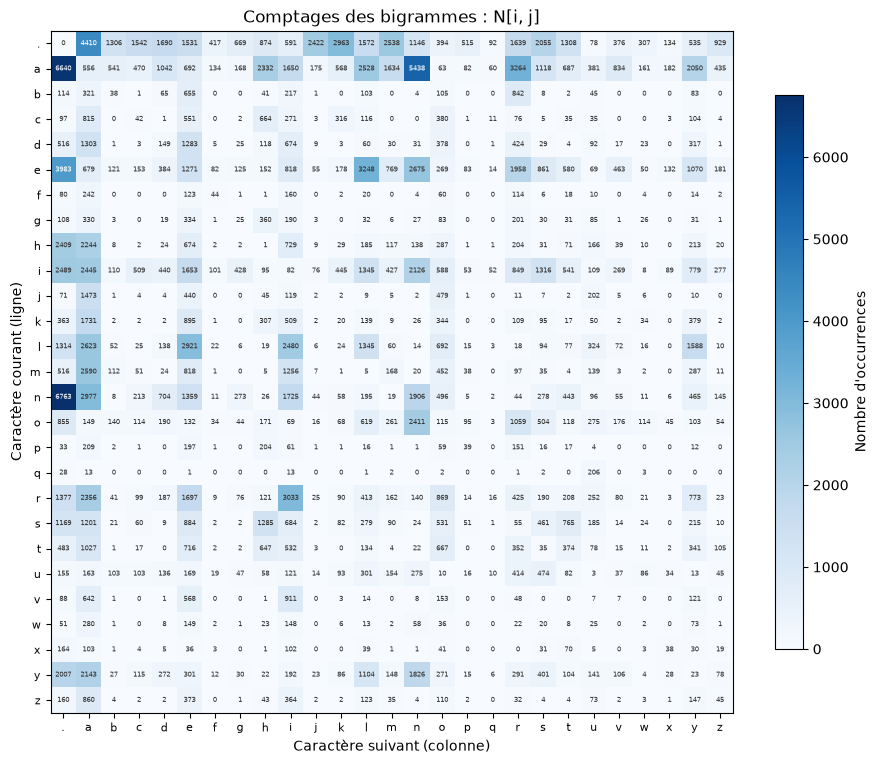

In [5]:
assert N.sum().item() == sum(longueurs) + len(words)
print("Contrôle OK :", sum(longueurs), "lettres +", len(words), "prénoms =", N.sum().item())

plot_matrice_caracteres(N, itos, title="Comptages des bigrammes : N[i, j]",
                        cbar_label="Nombre d'occurrences", annoter=True, figsize=(11, 9))
plt.show()

**Lire la carte :** choisissez une ligne (caractère courant), puis une colonne (caractère suivant). Plus la case est foncée, plus la transition est fréquente.

- La **ligne `.`** donne les premières lettres des prénoms.
- La **colonne `.`** indique les lettres qui terminent souvent un prénom (`n`, `a`, `e`, `y`…).
- Beaucoup de cases sont presque blanches : certaines transitions sont rares, et quelques-unes n'apparaissent **jamais** (nous verrons au notebook 02 que c'est un problème).

Voici les transitions les plus fréquentes :

In [6]:
valeurs, positions = N.flatten().topk(10)
for v, pos in zip(valeurs, positions):
    i, j = divmod(pos.item(), 27)
    print(f"  {itos[i]} → {itos[j]} : {v.item():5d}")
print("Cases à zéro :", (N == 0).sum().item(), "sur 729")

  n → . :  6763
  a → . :  6640
  a → n :  5438
  . → a :  4410
  e → . :  3983
  a → r :  3264
  e → l :  3248
  r → i :  3033
  n → a :  2977
  . → k :  2963
Cases à zéro : 102 sur 729


## 3. Des comptages aux probabilités

Une **distribution de probabilité** est un ensemble de valeurs **positives ou nulles** dont la somme vaut **1**. Pour un caractère courant `i`, on divise chaque case de la ligne par le total de la ligne :

$$
P(j\mid i)=\frac{N_{ij}}{\sum_k N_{ik}}.
$$

**Pourquoi diviser par la somme de la ligne ?** Imaginons que la ligne de `a` ne contienne que trois issues : `m : 30`, `n : 10`, `. : 10`. Sur **50** occurrences de `a` comme caractère courant, `m` vient ensuite 30 fois, d'où

$$
P(m\mid a) = \frac{30}{50} = 0{,}60.
$$

Autrement dit : « parmi les fois où le caractère courant est `a`, 60 % sont suivies de `m` ». On divise **ligne par ligne** parce qu'on conditionne sur le caractère courant : la distribution après `a` n'est pas celle après `m`.

Commençons par la ligne `.`, qui donne la **première lettre** d'un prénom.

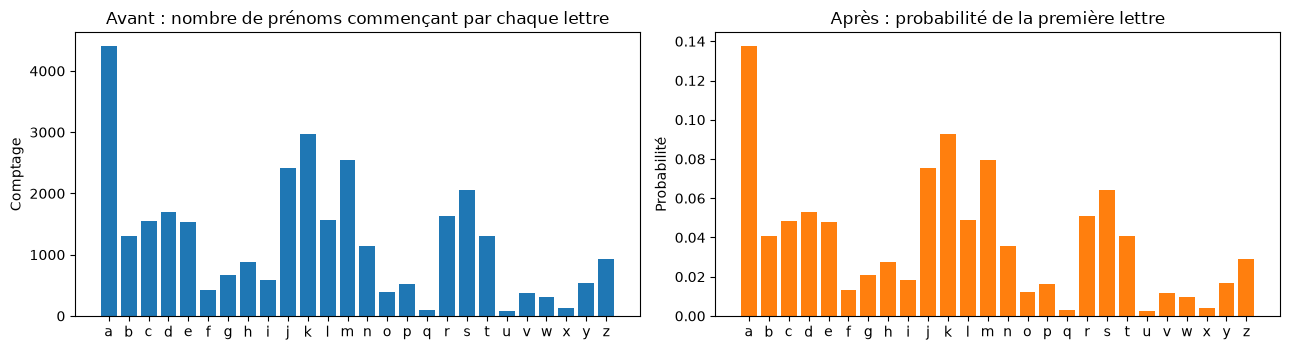

Somme de la ligne après normalisation : 1.0


In [7]:
start_counts = N[0].float()
start_probs = start_counts / start_counts.sum()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(chars, start_counts[1:].numpy())
ax[0].set_title("Avant : nombre de prénoms commençant par chaque lettre")
ax[0].set_ylabel("Comptage")
ax[1].bar(chars, start_probs[1:].numpy(), color="tab:orange")
ax[1].set_title("Après : probabilité de la première lettre")
ax[1].set_ylabel("Probabilité")
plt.tight_layout(); plt.show()
print("Somme de la ligne après normalisation :", round(start_probs.sum().item(), 6))

Les deux graphiques ont **exactement la même forme** : seule l'échelle verticale change. Normaliser ne change pas les préférences, cela les rend comparables d'une ligne à l'autre.

### Normaliser toutes les lignes d'un coup… et le piège du broadcasting

On veut diviser chaque ligne de `N` par **sa propre** somme. `N.sum(dim=1, keepdim=True)` donne un vecteur colonne de forme `(27, 1)`. PyTorch le « recopie » sur les 27 colonnes : c'est le **broadcasting**.

**Piège classique :** sans `keepdim=True`, la somme a la forme `(27,)`. PyTorch l'interprète alors comme une **ligne** `(1, 27)` et divise chaque **colonne** par la somme d'une ligne. Le code ne plante pas, mais le résultat est faux. Vérifions.

In [8]:
sommes_lignes = N.sum(dim=1, keepdim=True)
print("Avec keepdim=True :", tuple(sommes_lignes.shape), " | sans :", tuple(N.sum(dim=1).shape))

P_faux = N.float() / N.sum(dim=1)                       # (27,27) / (27,)  -> divise les colonnes !
P = N.float() / N.sum(dim=1, keepdim=True)              # (27,27) / (27,1) -> divise les lignes

print("Sommes des lignes, version fausse   :", P_faux.sum(dim=1)[:5].round(decimals=3).tolist(), "…")
print("Sommes des lignes, version correcte :", P.sum(dim=1)[:5].round(decimals=3).tolist(), "…")
assert torch.allclose(P.sum(dim=1), torch.ones(27))

Avec keepdim=True : (27, 1)  | sans : (27,)
Sommes des lignes, version fausse   : [7.021999835968018, 4.414000034332275, 0.20100000500679016, 0.3720000088214874, 0.41499999165534973] …
Sommes des lignes, version correcte : [1.0, 1.0, 1.0, 1.0, 1.0] …


> **À retenir :** quand on normalise « par ligne », on écrit `sum(dim=1, keepdim=True)`. Vérifiez toujours qu'une distribution somme bien à 1 : c'est un test d'une ligne qui évite des heures de recherche d'erreur.

## 4. Tirer au sort le caractère suivant : `torch.multinomial`

Une ligne de `P` dit **à quel point** chaque caractère suivant est probable. Elle ne dit pas **lequel** sera tiré. C'est le rôle de `torch.multinomial`.

Avec trois issues `p = [0.6, 0.3, 0.1]` (pour `a`, `b`, `c`), on obtient **en moyenne** 60 % de `a`, 30 % de `b` et 10 % de `c`. Un tirage isolé peut très bien donner `c` : ce n'est pas une erreur.

- `num_samples=1` : on veut **un** caractère suivant ;
- `replacement=True` : autorise à retomber sur le même indice lors de tirages multiples ;
- `generator=g` : un générateur à graine fixe pour que tout le monde obtienne les mêmes tirages ;
- `.item()` : convertit le tenseur en entier Python.

In [9]:
g = torch.Generator().manual_seed(SEED)
p = torch.tensor([0.6, 0.3, 0.1])

print("Un tirage :", torch.multinomial(p, num_samples=1, replacement=True, generator=g).item())
tirages = torch.multinomial(p, num_samples=10_000, replacement=True, generator=g)
frequences = torch.bincount(tirages, minlength=3) / len(tirages)
print("Fréquences sur 10 000 tirages :", frequences.round(decimals=3).tolist(), " vs p =", p.tolist())

Un tirage : 0
Fréquences sur 10 000 tirages : [0.6019999980926514, 0.29600000381469727, 0.10199999809265137]  vs p = [0.6000000238418579, 0.30000001192092896, 0.10000000149011612]


**Ne pas confondre avec `argmax`.** `argmax` choisit **toujours** l'issue la plus probable : la génération devient déterministe et répétitive. `multinomial` laisse une chance aux autres issues, ce qui produit de la variété.

### Générer des prénoms

1. partir de `.` (indice 0) ;
2. tirer le caractère suivant dans la ligne `P[ix]` ;
3. ce caractère devient le nouveau caractère courant : on recommence avec **sa** ligne ;
4. s'arrêter quand on tire `.`.

In [10]:
def sample_names_from_table(P, n=8, seed=SEED, argmax=False):
    g = torch.Generator().manual_seed(seed)
    results = []
    for _ in range(n):
        out, ix = [], 0
        for _ in range(40):                       # garde-fou : 40 caractères au plus
            if argmax:
                ix = P[ix].argmax().item()
            else:
                ix = torch.multinomial(P[ix], 1, replacement=True, generator=g).item()
            if ix == 0:
                break
            out.append(itos[ix])
        results.append("".join(out))
    return results

print("Avec multinomial :", sample_names_from_table(P, 10))
print("Avec argmax      :", sample_names_from_table(P, 3, argmax=True))

Avec multinomial : ['cexze', 'momasurailezitynn', 'konimittain', 'llayn', 'ka', 'da', 'staiyaubrtthrigotai', 'moliellavo', 'ke', 'teda']
Avec argmax      : ['a', 'a', 'a']


Avec `argmax`, tous les prénoms sont identiques et réduits à `a`. Après `.`, la lettre la plus fréquente est `a`. Après `a`, le symbole le plus fréquent est `.` (beaucoup de prénoms finissent par *a*). Le chemin « le plus probable » s'arrête donc immédiatement.

### Est-ce mieux que le hasard ?

Comparons avec un modèle **uniforme**, qui donne `1/27` à chaque caractère dans toutes les lignes. Il n'a rien appris du corpus.

In [11]:
P_uniforme = torch.ones(27, 27) / 27
print("Modèle uniforme :", sample_names_from_table(P_uniforme, 6))
print("Modèle bigramme :", sample_names_from_table(P, 6))

ensemble = set(words)
generes = sample_names_from_table(P, 1000, seed=0)
print(f"\nSur 1000 prénoms générés, {sum(g in ensemble for g in generes)} existent déjà dans names.txt")
print("Longueur moyenne générée :", round(sum(map(len, generes)) / 1000, 1), " | réelle :",
      round(sum(longueurs) / len(longueurs), 1))

Modèle uniforme : ['cexzm', 'zoglkurkicqzktyhwmvmzimjttainrlkfukzkktd', 'a', 'sfcxvpubjtbhrmgotzx', 'iczixqctvujkwptedogkkjemkmmsidguenkbvgyn', 'ywftbspmhwcivgbvtahlvsu']
Modèle bigramme : ['cexze', 'momasurailezitynn', 'konimittain', 'llayn', 'ka', 'da']

Sur 1000 prénoms générés, 102 existent déjà dans names.txt
Longueur moyenne générée : 6.3  | réelle : 6.1


**Discussion :**
- Le modèle uniforme produit des chaînes très longues et imprononçables : il tire `.` seulement une fois sur 27.
- Le bigramme a appris des choses réelles : quelles lettres commencent et finissent un prénom, quelles lettres s'enchaînent. Ses longueurs sont proches des vraies.
- Mais ses prénoms restent souvent **incohérents dans l'ensemble**. Il ne connaît **que le dernier caractère** : il n'a aucune mémoire de la syllabe ni de la longueur déjà écrite.

## Bilan

| Étape | Code | Ce que l'on obtient |
|---|---|---|
| Compter | `N[stoi[ch1], stoi[ch2]] += 1` | 729 compteurs |
| Normaliser | `P = N / N.sum(1, keepdim=True)` | 27 distributions, une par caractère courant |
| Générer | `torch.multinomial(P[ix], 1)` en boucle | des prénoms nouveaux |

**La question qui lance le notebook 02 :** les prénoms « ont l'air » meilleurs qu'avec le modèle uniforme. Mais comment le **mesurer** avec un nombre ? Il nous faut une note objective, et ce sera la **loss**.

## Références
- C. E. Shannon, [*A Mathematical Theory of Communication*](https://people.math.harvard.edu/~ctm/home/text/others/shannon/entropy/entropy.pdf), 1948, section 3 : les approximations de l'anglais par des chaînes de lettres.
- D. Jurafsky et J. H. Martin, [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), chapitre 3 « N-gram Language Models ».
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) et le dépôt [makemore](https://github.com/karpathy/makemore), dont viennent `names.txt` et l'esprit de ce chapitre.
- Documentation PyTorch : [broadcasting](https://pytorch.org/docs/stable/notes/broadcasting.html), [`torch.multinomial`](https://pytorch.org/docs/stable/generated/torch.multinomial.html).